In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

print("All libraries imported successfully!")

All libraries imported successfully!


In [6]:
import pandas as pd

df = pd.read_csv(
    r"C:\Users\rajka\OneDrive\Documents\Datheon_Task_3_Customer_Cohort_Churn_Analytics\telco_customer_churn.csv"
)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
print("Dataset Information:")
df.info()

print("\nDataset Columns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  704

In [8]:
print("TotalCharges Data Type:", df["TotalCharges"].dtype)

print("\nSample TotalCharges Values:")
print(df["TotalCharges"].head(20).tolist())

print("\nBlank or Empty Values:")
print((df["TotalCharges"].str.strip() == "").sum())

TotalCharges Data Type: object

Sample TotalCharges Values:
['29.85', '1889.5', '108.15', '1840.75', '151.65', '820.5', '1949.4', '301.9', '3046.05', '3487.95', '587.45', '326.8', '5681.1', '5036.3', '2686.05', '7895.15', '1022.95', '7382.25', '528.35', '1862.9']

Blank or Empty Values:
11


In [9]:
# Convert TotalCharges into numeric format
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"].str.strip(),
    errors="coerce"
)

# Check missing values again
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

# Display data type
print("New Data Type:", df["TotalCharges"].dtype)

Missing TotalCharges: 11
New Data Type: float64


In [10]:
missing_customers = df[df["TotalCharges"].isnull()]

print("Number of affected customers:", len(missing_customers))

missing_customers[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Number of affected customers: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No


In [13]:
# Replace missing TotalCharges with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Verify missing values
print("Missing values after cleaning:", df.isnull().sum().sum())

# Check TotalCharges data type
print("TotalCharges Data Type:", df["TotalCharges"].dtype)

Missing values after cleaning: 0
TotalCharges Data Type: float64


In [14]:
# Count total customers
total_customers = df.shape[0]

# Count customers who churned
churned_customers = (df["Churn"] == "Yes").sum()

# Calculate churn rate
churn_rate = (churned_customers / total_customers) * 100

print("Total Customers:", total_customers)
print("Churned Customers:", churned_customers)
print("Baseline Churn Rate:", round(churn_rate, 2), "%")

Total Customers: 7043
Churned Customers: 1869
Baseline Churn Rate: 26.54 %


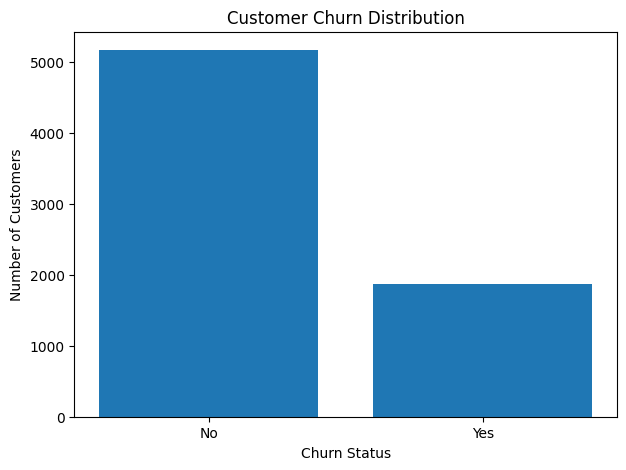

In [15]:
import matplotlib.pyplot as plt

churn_counts = df["Churn"].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(churn_counts.index, churn_counts.values)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.show()

In [16]:
print("Customer Tenure Statistics:")
print(df["tenure"].describe())

Customer Tenure Statistics:
count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64


In [17]:
bins = [0, 12, 24, 48, 72]

labels = [
    "0-12 Months",
    "13-24 Months",
    "25-48 Months",
    "49-72 Months"
]

df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

print(df["TenureGroup"].value_counts().sort_index())

TenureGroup
0-12 Months     2186
13-24 Months    1024
25-48 Months    1594
49-72 Months    2239
Name: count, dtype: int64


In [18]:
tenure_churn = df.groupby(
    "TenureGroup",
    observed=False
)["Churn"].value_counts().unstack()

tenure_churn["ChurnRate"] = (
    tenure_churn["Yes"] /
    (tenure_churn["Yes"] + tenure_churn["No"])
) * 100

print(tenure_churn.round(2))

Churn           No   Yes  ChurnRate
TenureGroup                        
0-12 Months   1149  1037      47.44
13-24 Months   730   294      28.71
25-48 Months  1269   325      20.39
49-72 Months  2026   213       9.51


In [19]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"]
)

contract_churn["ChurnRate"] = (
    contract_churn["Yes"] /
    contract_churn.sum(axis=1)
) * 100

print(contract_churn.round(2))

Churn             No   Yes  ChurnRate
Contract                             
Month-to-month  2220  1655      42.71
One year        1307   166      11.27
Two year        1647    48       2.83


In [20]:
payment_churn = pd.crosstab(
    df["PaymentMethod"],
    df["Churn"]
)

payment_churn["ChurnRate"] = (
    payment_churn["Yes"] /
    payment_churn.sum(axis=1)
) * 100

print(payment_churn.round(2))

Churn                        No   Yes  ChurnRate
PaymentMethod                                   
Bank transfer (automatic)  1286   258      16.71
Credit card (automatic)    1290   232      15.24
Electronic check           1294  1071      45.29
Mailed check               1304   308      19.11


In [21]:
monthly_charges = df.groupby("Churn")["MonthlyCharges"].mean()

print("Average Monthly Charges by Churn Status:")
print(monthly_charges.round(2))

Average Monthly Charges by Churn Status:
Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


In [22]:
risk_analysis = df.pivot_table(
    index="Contract",
    columns="TenureGroup",
    values="Churn",
    aggfunc=lambda x: (x == "Yes").mean() * 100,
    observed=False
)

print("Churn Rate by Contract and Tenure:")
print(risk_analysis.round(2))

Churn Rate by Contract and Tenure:
TenureGroup     0-12 Months  13-24 Months  25-48 Months  49-72 Months
Contract                                                             
Month-to-month        51.35         37.72         32.92         26.02
One year              10.48          8.12         10.62         12.93
Two year               0.00          0.00          2.19          3.33


In [23]:
print("Date-related columns:")

print([
    col for col in df.columns
    if "date" in col.lower() or "month" in col.lower()
])

Date-related columns:
['MonthlyCharges']


In [24]:
retention_matrix = pd.crosstab(
    df["TenureGroup"],
    df["Churn"],
    normalize="index"
) * 100

retention_matrix = retention_matrix.rename(
    columns={"No": "Retained %", "Yes": "Churned %"}
)

print(retention_matrix.round(2))

Churn         Retained %  Churned %
TenureGroup                        
0-12 Months        52.56      47.44
13-24 Months       71.29      28.71
25-48 Months       79.61      20.39
49-72 Months       90.49       9.51


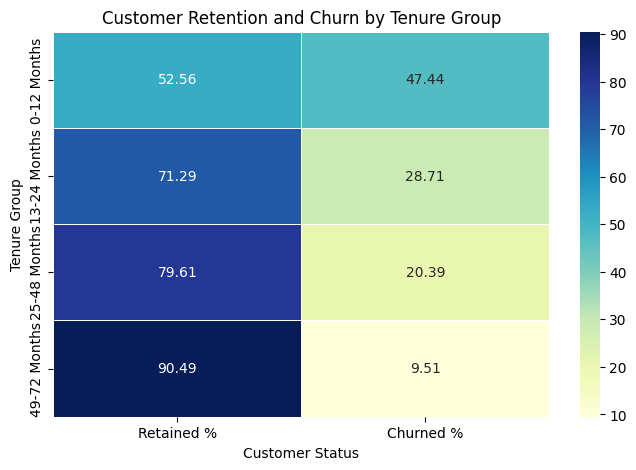

In [25]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    retention_matrix,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Customer Retention and Churn by Tenure Group")
plt.xlabel("Customer Status")
plt.ylabel("Tenure Group")

plt.show()